# Conceptos básicos de posición y radiación solar con `pvlib`

Este cuaderno presenta un ejemplo introductorio para Puebla. Se calcularán la posición solar, las componentes DNI, DHI y GHI, el ángulo de incidencia sobre un plano inclinado, la irradiancia en el plano del arreglo y las trayectorias solares representativas.


## Objetivos

- Interpretar `apparent_elevation`, `apparent_zenith` y `azimuth`.
- Distinguir DNI, DHI y GHI.
- Relacionar la orientación de una superficie con `aoi`.
- Calcular las componentes de irradiancia en el plano del arreglo.
- Representar la trayectoria solar mediante un diagrama polar.


In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pvlib.location import Location
from pvlib import irradiance

plt.style.use("seaborn-v0_8-whitegrid")
pd.options.display.float_format = lambda valor: f"{valor:,.2f}"

## 1. Sitio y fecha de análisis

Se utiliza una ubicación representativa de Puebla y el equinoccio de marzo de 2026. La zona horaria es indispensable para relacionar correctamente la hora civil con la posición solar.

In [73]:
latitude = 19.04
longitude = -98.20
altitude = 2160
timezone = "America/Mexico_City" 

sitio = Location(
    latitude=latitude,
    longitude=longitude,
    tz=timezone,
    altitude=altitude,
    name="Puebla",
)

times = pd.date_range(
    start="2026-03-20 05:00",
    end="2026-03-20 20:00",
    freq="5min",
    tz=timezone,
)

In [74]:
print(times)

DatetimeIndex(['2026-03-20 05:00:00-06:00', '2026-03-20 05:05:00-06:00',
               '2026-03-20 05:10:00-06:00', '2026-03-20 05:15:00-06:00',
               '2026-03-20 05:20:00-06:00', '2026-03-20 05:25:00-06:00',
               '2026-03-20 05:30:00-06:00', '2026-03-20 05:35:00-06:00',
               '2026-03-20 05:40:00-06:00', '2026-03-20 05:45:00-06:00',
               ...
               '2026-03-20 19:15:00-06:00', '2026-03-20 19:20:00-06:00',
               '2026-03-20 19:25:00-06:00', '2026-03-20 19:30:00-06:00',
               '2026-03-20 19:35:00-06:00', '2026-03-20 19:40:00-06:00',
               '2026-03-20 19:45:00-06:00', '2026-03-20 19:50:00-06:00',
               '2026-03-20 19:55:00-06:00', '2026-03-20 20:00:00-06:00'],
              dtype='datetime64[us, America/Mexico_City]', length=181, freq='5min')


## 2. Posición solar

`pvlib` devuelve la elevación y el ángulo cenital, tanto geométricos como aparentes. El acimut se mide desde el norte en sentido horario: norte 0°, este 90°, sur 180° y oeste 270°.

In [75]:
posicion = sitio.get_solarposition(times)
posicion_dia = posicion.loc[posicion["apparent_elevation"] > 0].copy()

indice_mediodia = posicion_dia["apparent_elevation"].idxmax()
resumen_mediodia = posicion_dia.loc[
    [indice_mediodia],
    ["apparent_elevation", "apparent_zenith", "azimuth"],
].rename(columns={
    "apparent_elevation": "Elevación aparente [°]",
    "apparent_zenith": "Cenital aparente [°]",
    "azimuth": "Acimut [°]",
})

display(resumen_mediodia)

,Elevación aparente [°],Cenital aparente [°],Acimut [°]
2026-03-20 12:40:00-06:00,71.03,18.97,179.88


In [76]:
print(indice_mediodia)

2026-03-20 12:40:00-06:00


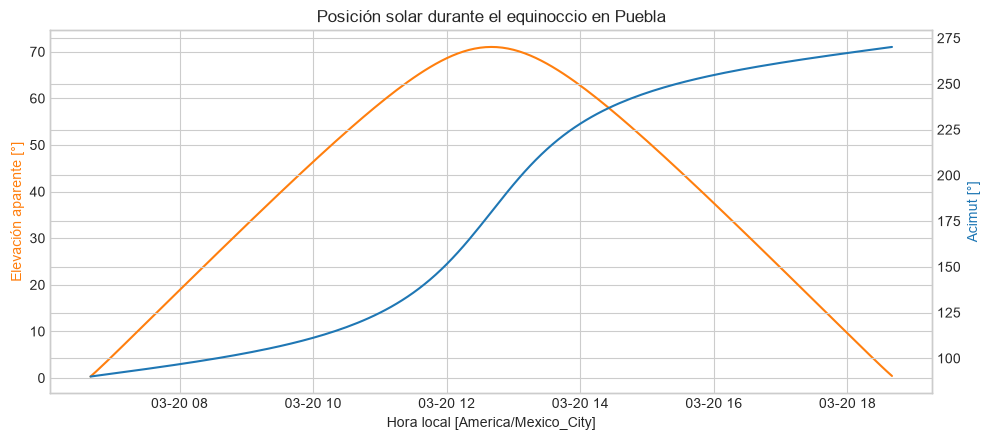

In [77]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(
    posicion_dia.index,
    posicion_dia["apparent_elevation"],
    color="tab:orange",
    label="apparent_elevation",
)
ax1.set_ylabel("Elevación aparente [°]", color="tab:orange")
ax1.set_xlabel(f"Hora local [{timezone}]")

ax2 = ax1.twinx()
ax2.plot(
    posicion_dia.index,
    posicion_dia["azimuth"],
    color="tab:blue",
    label="azimuth",
)
ax2.set_ylabel("Acimut [°]", color="tab:blue")
ax1.set_title("Posición solar durante el equinoccio en Puebla")
fig.tight_layout()
plt.show()

## 3. DNI, DHI y GHI

Se utilizará el modelo de cielo despejado de Ineichen incluido en `pvlib` para generar un conjunto coherente de DNI, DHI y GHI en condiciones ideales.

- **DNI:** irradiancia directa normal a los rayos solares.
- **DHI:** irradiancia difusa recibida por una superficie horizontal.
- **GHI:** irradiancia global recibida por una superficie horizontal.

La relación entre las componentes es

$$
mathrm{GHI}=mathrm{DNI}cos(mathrm{zenith})+mathrm{DHI}.
$$

Ineichen genera las componentes de cielo despejado. No es el modelo de transposición al plano inclinado.


In [78]:
cielo_claro = sitio.get_clearsky(posicion_dia.index, model="ineichen")
datos = posicion_dia.join(cielo_claro)

cos_zenith = np.clip(
    np.cos(np.radians(datos["zenith"])),
    0,
    None,
)
datos["ghi_calculada"] = datos["dni"] * cos_zenith + datos["dhi"]
datos["error_balance"] = datos["ghi_calculada"] - datos["ghi"]

indice_maximo = datos["ghi"].idxmax()
tabla_componentes = datos.loc[
    [indice_maximo],
    ["dni", "dhi", "ghi", "ghi_calculada", "error_balance"],
].rename(columns={
    "dni": "DNI [W/m²]",
    "dhi": "DHI [W/m²]",
    "ghi": "GHI de pvlib [W/m²]",
    "ghi_calculada": "GHI calculada [W/m²]",
    "error_balance": "Diferencia [W/m²]",
})

display(tabla_componentes)

,DNI [W/m²],DHI [W/m²],GHI de pvlib [W/m²],GHI calculada [W/m²],Diferencia [W/m²]
2026-03-20 12:40:00-06:00,991.18,187.15,"1,124.48","1,124.46",-0.02


In [79]:
print(indice_maximo)

2026-03-20 12:40:00-06:00


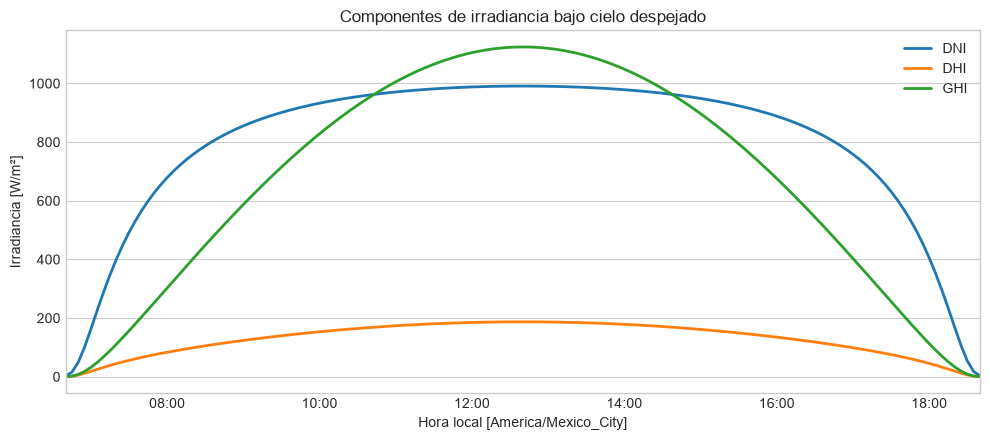

In [80]:
datos[["dni", "dhi", "ghi"]].plot(
    figsize=(10, 4.5),
    linewidth=2,
)
plt.title("Componentes de irradiancia bajo cielo despejado")
plt.xlabel(f"Hora local [{timezone}]")
plt.ylabel("Irradiancia [W/m²]")
plt.legend(["DNI", "DHI", "GHI"])
plt.tight_layout()
plt.show()

## 4. Irradiancia sobre un plano inclinado

Se analiza una superficie con `surface_tilt = 20°` y `surface_azimuth = 180°`. El ángulo de incidencia `aoi` mide la separación entre los rayos solares y la normal al plano.

La función `get_total_irradiance` utiliza `model="isotropic"` para calcular la componente difusa del cielo mediante el modelo isotrópico asociado con Liu y Jordan. El modelo recibe como datos de entrada DNI, DHI y GHI.


In [81]:
surface_tilt = 25.0
surface_azimuth = 180.0

datos["aoi"] = irradiance.aoi(
    surface_tilt=surface_tilt,
    surface_azimuth=surface_azimuth,
    solar_zenith=datos["apparent_zenith"],
    solar_azimuth=datos["azimuth"],
)

poa = irradiance.get_total_irradiance(
    surface_tilt=surface_tilt,
    surface_azimuth=surface_azimuth,
    solar_zenith=datos["apparent_zenith"],
    solar_azimuth=datos["azimuth"],
    dni=datos["dni"],
    ghi=datos["ghi"],
    dhi=datos["dhi"],
    albedo=0.20,
    model="isotropic",
)

datos = datos.join(poa)

tabla_plano = datos.loc[
    [indice_maximo],
    ["aoi", "poa_direct", "poa_sky_diffuse",
     "poa_ground_diffuse", "poa_global"],
].rename(columns={
    "aoi": "AOI [°]",
    "poa_direct": "POA directa [W/m²]",
    "poa_sky_diffuse": "POA difusa del cielo [W/m²]",
    "poa_ground_diffuse": "POA reflejada [W/m²]",
    "poa_global": "POA global [W/m²]",
})

display(tabla_plano)

,AOI [°],POA directa [W/m²],POA difusa del cielo [W/m²],POA reflejada [W/m²],POA global [W/m²]
2026-03-20 12:40:00-06:00,6.03,985.70,178.38,10.54,"1,174.61"


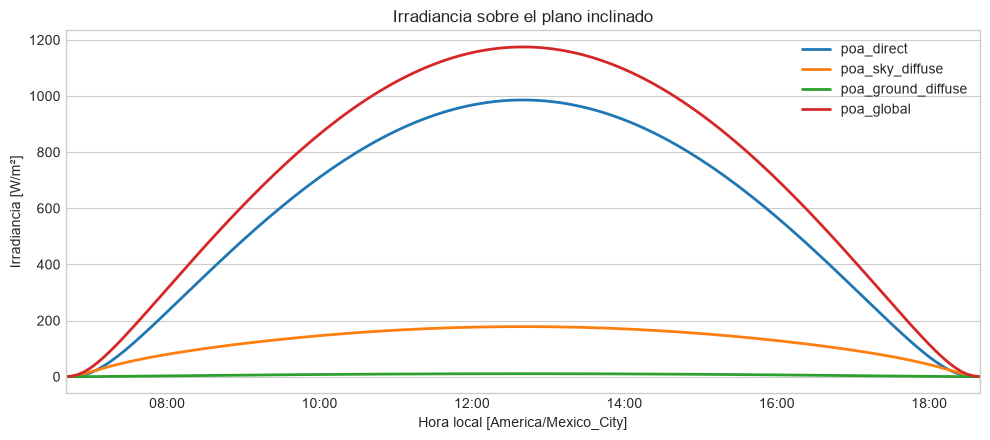

In [82]:
datos[["poa_direct", "poa_sky_diffuse",
       "poa_ground_diffuse", "poa_global"]].plot(
    figsize=(10, 4.5),
    linewidth=2,
)
plt.title("Irradiancia sobre el plano inclinado")
plt.xlabel(f"Hora local [{timezone}]")
plt.ylabel("Irradiancia [W/m²]")
plt.tight_layout()
plt.show()

## 5. Diagrama solar

El diagrama polar representa el acimut en la dirección angular y el ángulo cenital aparente en la dirección radial. El centro corresponde al cenit y el borde al horizonte.

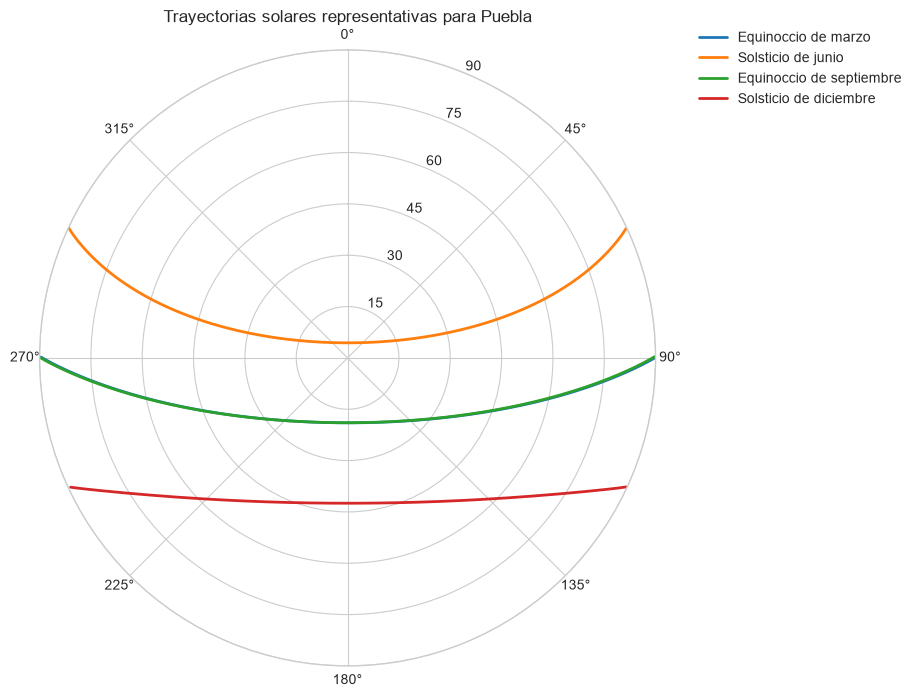

In [83]:
fechas = {
    "Equinoccio de marzo": "2026-03-20",
    "Solsticio de junio": "2026-06-21",
    "Equinoccio de septiembre": "2026-09-22",
    "Solsticio de diciembre": "2026-12-21",
}

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})

for etiqueta, fecha in fechas.items():
    tiempos_dia = pd.date_range(
        start=f"{fecha} 00:00",
        end=f"{fecha} 23:55",
        freq="5min",
        tz=timezone,
    )
    trayectoria = sitio.get_solarposition(tiempos_dia)
    trayectoria = trayectoria.loc[trayectoria["apparent_elevation"] > 0]
    ax.plot(
        np.radians(trayectoria["azimuth"]),
        trayectoria["apparent_zenith"],
        label=etiqueta,
        linewidth=2,
    )

ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_rmax(90)
ax.set_rticks([0, 15, 30, 45, 60, 75, 90])
ax.set_title("Trayectorias solares representativas para Puebla", pad=20)
ax.legend(loc="upper left", bbox_to_anchor=(1.05, 1.05))
plt.show()

## Interpretación

- La elevación solar alcanza su máximo cerca del mediodía solar, no necesariamente a las 12:00 de la hora civil.
- La DNI se proyecta sobre una superficie mediante el coseno del ángulo de incidencia.
- `poa_global` reúne las componentes directa, difusa del cielo y reflejada por el terreno.
- La orientación del plano modifica `aoi` y, por tanto, la irradiancia directa recibida.
- Ineichen genera el caso de cielo despejado; `model="isotropic"` realiza la transposición al plano inclinado.
